# Сверточная сеть
В этом ноутбуке мы расширим предыдущий и создадим первую сверточную сеть

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [2]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist)


In [3]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

In [4]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [5]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

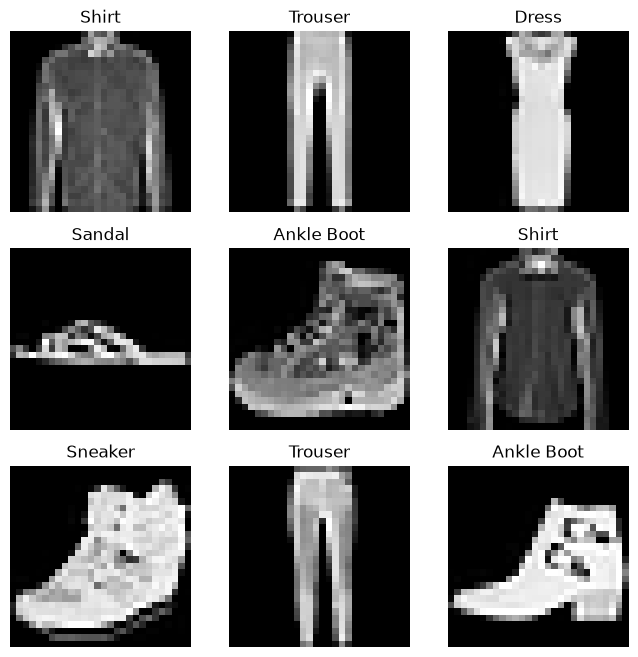

In [6]:
plot_samples(train_data, labels_map, cols=3, rows=3)

In [7]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


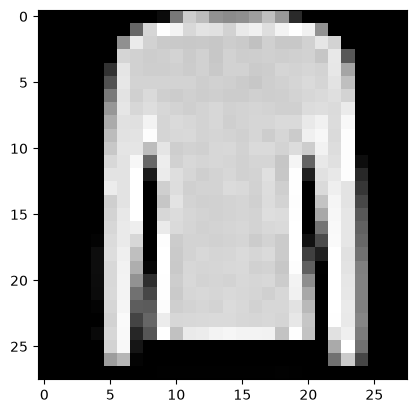

Label: 2


In [8]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cpu device


Теперь создадим класс модели и интстанциируем её. В данном случае это простая сверточная сеть: изображение проходит через блоки из сверток `nn.Conv2d` с batch-нормализацией (`nn.BatchNorm2d`) и активацией (`nn.ReLU`), а затем карта признаков разворачивается в вектор и подается в линейную голову `nn.Linear`, выдающую логиты для 10 классов. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.


### Архитектура модели

Схема ниже показывает названия слоев и размер выхода каждого слоя (для одного изображения):

![diagram](../images/simple_cnn.png)

In [10]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.head = nn.Linear(16*28*28, 10)

    def forward(self, x):
        x = self.base(x)
        # Необходимо превратить вход в вектор, чтобы можно было применить линейный слой

        x = x.view(x.size(0), -1)
        logits = self.head(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
  )
  (head): Linear(in_features=12544, out_features=10, bias=True)
)


Часто вместо решейпа перед головой используют пулинг. Это специальный слой, который накладывается на вход и позволяет получить его преобразование (max, avg) без весов:
![alt text](..\images\max_pool.png "Stride=1, padding=0")

Если сделать MaxPool2d или AvgPool2d с размером ядра, равным размеру входа, то получится вектор такого же размера, как исходное число каналов. Однако, все равно придется добавить дополнительное измерение.

**Задание**: Измените модель, используя MaxPool или AvgPool вместо view(). Сравните результаты.

In [11]:
class PooledNeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.pool = nn.MaxPool2d(kernel_size=28)
        self.head = nn.Linear(16, 10)

    def forward(self, x):
        x = self.base(x)
        x = self.pool(x)
        x = torch.flatten(x, start_dim=1)
        return self.head(x)

pooled_model = PooledNeuralNetwork().to(device)
print(pooled_model)


PooledNeuralNetwork(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
  )
  (pool): MaxPool2d(kernel_size=28, stride=28, padding=0, dilation=1, ceil_mode=False)
  (head): Linear(in_features=16, out_features=10, bias=True)
)


Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [12]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [13]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    batch_losses = []
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        # Compute prediction error
        preds = model(inputs)
        loss = loss_fn(preds, targets)
        batch_losses.append((loss.item(), len(inputs)))

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch_idx % 100 == 0:
            loss, current = loss.item(), (batch_idx + 1) * len(inputs)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
            
    return {
        "train_loss": sum(value * count for value, count in batch_losses) / size,
        "min_train_batch_loss": min(value for value, _ in batch_losses)
    }

In [14]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0, 0
    min_test_batch_loss = float("inf")
    confusion = torch.zeros((10, 10), dtype=torch.long, device=device)
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            preds = model(inputs)
            loss = loss_fn(preds, targets)
            test_loss += loss.item()
            min_test_batch_loss = min(min_test_batch_loss, loss.item())
            predicted_classes = preds.argmax(dim=1)
            confusion += torch.bincount(targets * 10 + predicted_classes, minlength=100).reshape(10, 10)
            num_correct += (preds.argmax(1) == targets).type(torch.float).sum().item()
    test_loss /= num_batches
    num_correct /= size
    print(f"Test Error: \n Accuracy: {(100*num_correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    
    true_positives = confusion.diag().float()
    precision = (true_positives / confusion.sum(dim=0).clamp(min=1)).mean().item()
    recall = (true_positives / confusion.sum(dim=1).clamp(min=1)).mean().item()
    print(f"Precision (macro): {100 * precision:.2f}%, Recall (macro): {100 * recall:.2f}%")
    return {
        "test_loss": test_loss,
        "min_test_batch_loss": min_test_batch_loss,
        "test_accuracy": 100 * num_correct,
        "test_precision_macro": 100 * precision,
        "test_recall_macro": 100 * recall
    }

Задание: Добавьте метрики precision и recall для проверки

In [15]:
epochs = 10
baseline_history = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_metrics = train(train_dataloader, model, loss_fn, optimizer)
    test_metrics = test(test_dataloader, model, loss_fn)
    baseline_history.append({"epoch": t + 1, **train_metrics, **test_metrics})


Epoch 1
-------------------------------
loss: 2.358121  [   64/60000]
loss: 0.913327  [ 6464/60000]
loss: 0.519142  [12864/60000]
loss: 0.581213  [19264/60000]
loss: 0.529787  [25664/60000]
loss: 0.558795  [32064/60000]
loss: 0.377556  [38464/60000]
loss: 0.369938  [44864/60000]
loss: 0.542148  [51264/60000]
loss: 0.493447  [57664/60000]
Test Error: 
 Accuracy: 84.2%, Avg loss: 0.452835 

Precision (macro): 84.27%, Recall (macro): 84.20%
Epoch 2
-------------------------------
loss: 0.471964  [   64/60000]
loss: 0.421865  [ 6464/60000]
loss: 0.573964  [12864/60000]
loss: 0.365634  [19264/60000]
loss: 0.343631  [25664/60000]
loss: 0.168875  [32064/60000]
loss: 0.309847  [38464/60000]
loss: 0.380935  [44864/60000]
loss: 0.273935  [51264/60000]
loss: 0.381546  [57664/60000]
Test Error: 
 Accuracy: 86.0%, Avg loss: 0.400185 

Precision (macro): 85.93%, Recall (macro): 85.97%
Epoch 3
-------------------------------
loss: 0.342346  [   64/60000]
loss: 0.383238  [ 6464/60000]
loss: 0.423228  

In [16]:
def summarize_history(name, network, history):
    best_epoch = max(history, key=lambda row: row["test_accuracy"])
    return {
        "Модель": name,
        "Параметры": sum(param.numel() for param in network.parameters()),
        "Мин. train loss": min(row["train_loss"] for row in history),
        "Мин. test loss": min(row["test_loss"] for row in history),
        "Лучшая accuracy, %": best_epoch["test_accuracy"],
        "Precision (macro), %": best_epoch["test_precision_macro"],
        "Recall (macro), %": best_epoch["test_recall_macro"],
    }


pooled_optimizer = torch.optim.SGD(pooled_model.parameters(), lr=1e-3)
pooled_history = []
for t in range(epochs):
    print(f"MaxPool, epoch {t + 1}/{epochs}")
    train_metrics = train(train_dataloader, pooled_model, loss_fn, pooled_optimizer)
    test_metrics = test(test_dataloader, pooled_model, loss_fn)
    pooled_history.append({"epoch": t + 1, **train_metrics, **test_metrics})

comparison_table = pd.DataFrame([
    summarize_history("Базовая CNN", model, baseline_history),
    summarize_history("CNN с MaxPool", pooled_model, pooled_history),
])
display(comparison_table.round(4))


MaxPool, epoch 1/10
loss: 4.080720  [   64/60000]
loss: 2.219968  [ 6464/60000]
loss: 2.045238  [12864/60000]
loss: 2.003969  [19264/60000]
loss: 1.838956  [25664/60000]
loss: 1.686604  [32064/60000]
loss: 1.568962  [38464/60000]
loss: 1.565639  [44864/60000]
loss: 1.490523  [51264/60000]
loss: 1.350913  [57664/60000]
Test Error: 
 Accuracy: 51.8%, Avg loss: 1.472303 

Precision (macro): 49.99%, Recall (macro): 51.84%
MaxPool, epoch 2/10
loss: 1.390932  [   64/60000]
loss: 1.476421  [ 6464/60000]
loss: 1.398462  [12864/60000]
loss: 1.302201  [19264/60000]
loss: 1.231922  [25664/60000]
loss: 1.266239  [32064/60000]
loss: 1.293319  [38464/60000]
loss: 1.324102  [44864/60000]
loss: 1.259609  [51264/60000]
loss: 1.020085  [57664/60000]
Test Error: 
 Accuracy: 61.0%, Avg loss: 1.167540 

Precision (macro): 60.07%, Recall (macro): 60.98%
MaxPool, epoch 3/10
loss: 1.214973  [   64/60000]
loss: 0.938948  [ 6464/60000]
loss: 1.332209  [12864/60000]
loss: 0.965051  [19264/60000]
loss: 1.260993  

,Модель,Параметры,Мин. train loss,Мин. test loss,"Лучшая accuracy, %","Precision (macro), %","Recall (macro), %"
0,Базовая CNN,130490,0.2500,0.2952,89.28,89.2359,89.28
1,CNN с MaxPool,5210,0.7249,0.7423,74.38,74.6449,74.38


ОТВЕТ: Глобальный MaxPool2d сводит каждую из 16 карт признаков к одному числу. Размер входа линейного слоя уменьшается с 16 × 28 × 28 до 16, поэтому модель с пулингом имеет значительно меньше обучаемых параметров. Обе модели обучаются с одинаковыми функцией потерь, оптимизатором, скоростью обучения и количеством эпох. В таблице выше приведены минимальные потери на обучающей и тестовой выборках, а также лучшие accuracy, precision и recall.

Осталось сохранить модель для дальнейшего использования.

In [17]:
torch.save(model.state_dict(), "simple_cnn_baseline.pth")
torch.save(pooled_model.state_dict(), "simple_cnn_maxpool.pth")

Задание: придумайте свою собственную модель, на следующем занятии сравнимся, у кого получилось достичь наилучших результатов.

In [18]:
class MyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(42)
my_model = MyCNN().to(device)
my_optimizer = torch.optim.AdamW(my_model.parameters(), lr=1e-3, weight_decay=1e-4)
my_history = []
for t in range(epochs):
    print(f"MyCNN, epoch {t + 1}/{epochs}")
    train_metrics = train(train_dataloader, my_model, loss_fn, my_optimizer)
    test_metrics = test(test_dataloader, my_model, loss_fn)
    my_history.append({"epoch": t + 1, **train_metrics, **test_metrics})

comparison_table = pd.concat([
    comparison_table,
    pd.DataFrame([summarize_history("Моя CNN (AdamW)", my_model, my_history)])
], ignore_index=True)
display(comparison_table.round(4))
torch.save(my_model.state_dict(), "simple_cnn_custom.pth")


MyCNN, epoch 1/10
loss: 2.465334  [   64/60000]
loss: 0.745034  [ 6464/60000]
loss: 0.426304  [12864/60000]
loss: 0.516096  [19264/60000]
loss: 0.202395  [25664/60000]
loss: 0.311746  [32064/60000]
loss: 0.339671  [38464/60000]
loss: 0.269195  [44864/60000]
loss: 0.375074  [51264/60000]
loss: 0.367608  [57664/60000]
Test Error: 
 Accuracy: 89.3%, Avg loss: 0.294551 

Precision (macro): 89.42%, Recall (macro): 89.31%
MyCNN, epoch 2/10
loss: 0.268862  [   64/60000]
loss: 0.241637  [ 6464/60000]
loss: 0.163968  [12864/60000]
loss: 0.243495  [19264/60000]
loss: 0.256818  [25664/60000]
loss: 0.354709  [32064/60000]
loss: 0.206604  [38464/60000]
loss: 0.148892  [44864/60000]
loss: 0.552576  [51264/60000]
loss: 0.311942  [57664/60000]
Test Error: 
 Accuracy: 90.7%, Avg loss: 0.254605 

Precision (macro): 90.84%, Recall (macro): 90.72%
MyCNN, epoch 3/10
loss: 0.210866  [   64/60000]
loss: 0.235628  [ 6464/60000]
loss: 0.261351  [12864/60000]
loss: 0.220720  [19264/60000]
loss: 0.230752  [25664

,Модель,Параметры,Мин. train loss,Мин. test loss,"Лучшая accuracy, %","Precision (macro), %","Recall (macro), %"
0,Базовая CNN,130490,0.2500,0.2952,89.28,89.2359,89.28
1,CNN с MaxPool,5210,0.7249,0.7423,74.38,74.6449,74.38
2,Моя CNN (AdamW),458890,0.0980,0.2133,92.83,92.8255,92.83


ОТВЕТ: Собственная модель использует три сверточных слоя, batch-нормализацию, два слоя MaxPool2d и dropout перед классификацией. Для неё выбран оптимизатор AdamW. Таблица выше позволяет сравнить достигнутые метрики с базовой и упрощённой моделями; при оценке нужно учитывать, что для собственной модели изменены и архитектура, и оптимизатор.